In [8]:
'''
This is the prototype of their SNN, which uses simple regression, but with 2 different models, that have 100 output neurons instead of 200. 
The idea is that SBP and DBP predictions are separate so they can use their own input features and weights to more accurately predict SBP and DBP values


[spikegen] Final CV MAE's: 
SBP: 12.6850 ± 1.9095
DBP: 7.6747 ± 1.7814



[spikegen] Final CV MAE's: 
SBP: 11.4698 ± 2.8030
DBP: 7.4079 ± 0.9795
'''
import torch
import torch.nn as nn
import torch.optim as optim
import snntorch as snn
from snntorch import spikegen
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from snntorch import surrogate, functional as SF
from scipy.stats import beta as beta_dist
import pickle
import matplotlib.pyplot as plt


In [9]:
def plot_predictions(all_true, all_predictions, label, fold):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].scatter(all_true, all_predictions, alpha=0.4, s=10)
    axes[0].plot([all_true.min(), all_true.max()],
                 [all_true.min(), all_true.max()], 'r--', label='Perfect prediction')
    axes[0].set_xlabel(f"True {label}")
    axes[0].set_ylabel(f"Predicted {label}")
    axes[0].set_title(f"Fold {fold+1} - Predicted vs True {label}")
    axes[0].legend()

    axes[1].plot(all_true[:100], label=f'True {label}', alpha=0.8)
    axes[1].plot(all_predictions[:100], label=f'Predicted {label}', alpha=0.8)
    axes[1].set_xlabel("Sample")
    axes[1].set_ylabel(f"{label} (mmHg)")
    axes[1].set_title(f"Fold {fold+1} - First 100 Samples")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [10]:
def combined_beta_cdf(vsignal):
    v = float(vsignal)
    if v < 0.5:
        vnorm = 2 * v
        return beta_dist.cdf(vnorm, a=1.0, b=0.75)
    else:
        vnorm = 2 * v - 1
        return beta_dist.cdf(vnorm, a=0.75, b=1.0)

'''
def rate_encoding_beta(X, timesteps=50):
    batch_size, N_features = X.shape
    spike_train = torch.zeros(timesteps, batch_size, N_features)
    for b in range(batch_size):
        for f in range(N_features):
            Pfr = combined_beta_cdf(X[b, f])
            spike_train[:, b, f] = torch.bernoulli(Pfr * torch.ones(timesteps))
    return spike_train
'''

def rate_encoding_beta(X, timesteps=50):
    # compute all beta CDF values at once using numpy, then convert back to tensor
    X_np  = X.clamp(0.0, 1.0).numpy()
    probs = np.vectorize(combined_beta_cdf)(X_np)
    probs = torch.tensor(probs, dtype=torch.float32)
    probs = probs.unsqueeze(0).expand(timesteps, -1, -1)
    return torch.bernoulli(probs)


'''
def rate_encoding_uniform(X, timesteps=50):
    batch_size, N_features = X.shape
    spike_train = torch.zeros(timesteps, batch_size, N_features)
    for b in range(batch_size):
        for f in range(N_features):
            Pfr = X[b, f]
            spike_train[:, b, f] = torch.bernoulli(Pfr * torch.ones(timesteps))
    return spike_train
'''

def rate_encoding_uniform(X, timesteps=50):
    probs = X.clamp(0.0, 1.0).unsqueeze(0).expand(timesteps, -1, -1)  # [T, batch, features]
    return torch.bernoulli(probs)   

def encode_batch(x, num_steps, method):
    '''
    x      : [batch, n_features] normalized to [0,1]
    method : 'spikegen' | 'uniform' | 'beta'
    Returns: [num_steps, batch, n_features]
    '''
    if method == 'spikegen':
        return spikegen.rate(x, num_steps=num_steps)
    elif method == 'uniform':
        return rate_encoding_uniform(x, timesteps=num_steps)
    elif method == 'beta':
        return rate_encoding_beta(x, timesteps=num_steps)
    else:
        raise ValueError(f'Unknown encoding: {method}')
    

In [11]:
num_steps = 40

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

class Net(nn.Module):
    def __init__(self, num_inputs, num_hidden, num_hidden2,
             num_outputs, beta_val, encoding_method):
        super().__init__()
        self.encoding_method = encoding_method
        self.fc1   = nn.Linear(num_inputs, num_hidden)
        self.lif1 = snn.Leaky(beta=beta_val, learn_beta=True)
        self.drop1 = nn.Dropout(p=0.3)
        self.fc2   = nn.Linear(num_hidden, num_hidden2)
        self.lif2 = snn.Leaky(beta=beta_val, learn_beta=True)
        self.drop2 = nn.Dropout(p=0.3)
        self.fc3   = nn.Linear(num_hidden2, num_outputs)
        self.lif3 = snn.Leaky(beta=beta_val, learn_beta=True)

    def forward(self, xf):
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        mem3 = self.lif3.init_leaky()
        spk_rec = []
        input_spikes = encode_batch(xf.cpu(), num_steps, self.encoding_method).to(device)
        for t in range(num_steps):
            cur1 = self.fc1(input_spikes[t])
            spk1, mem1 = self.lif1(cur1, mem1)
            spk1 = self.drop1(spk1)          # <-- added
            cur2 = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)
            spk2 = self.drop2(spk2)          # <-- added
            cur3 = self.fc3(spk2)
            spk3, mem3 = self.lif3(cur3, mem3)
            spk_rec.append(spk3)
        return torch.stack(spk_rec)

In [12]:
def get_closest_index(value, preferred_values):
    diffs = torch.abs(preferred_values - value)
    return int(torch.argmin(diffs).item())

In [13]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")


 ENCODING METHOD: SPIKEGEN

Fold 1/5
 Epoch 1 | Train Loss SBP: 6435.2485 | Train Loss DBP: 1763.0427
 Epoch 2 | Train Loss SBP: 138.3895 | Train Loss DBP: 56.4026
 Epoch 3 | Train Loss SBP: 127.2026 | Train Loss DBP: 44.7788
 Epoch 4 | Train Loss SBP: 123.9984 | Train Loss DBP: 39.7972
 Epoch 5 | Train Loss SBP: 118.9882 | Train Loss DBP: 37.4398
Generalization Error SBP = 15.1030, Generalization Error DBP = 10.5397


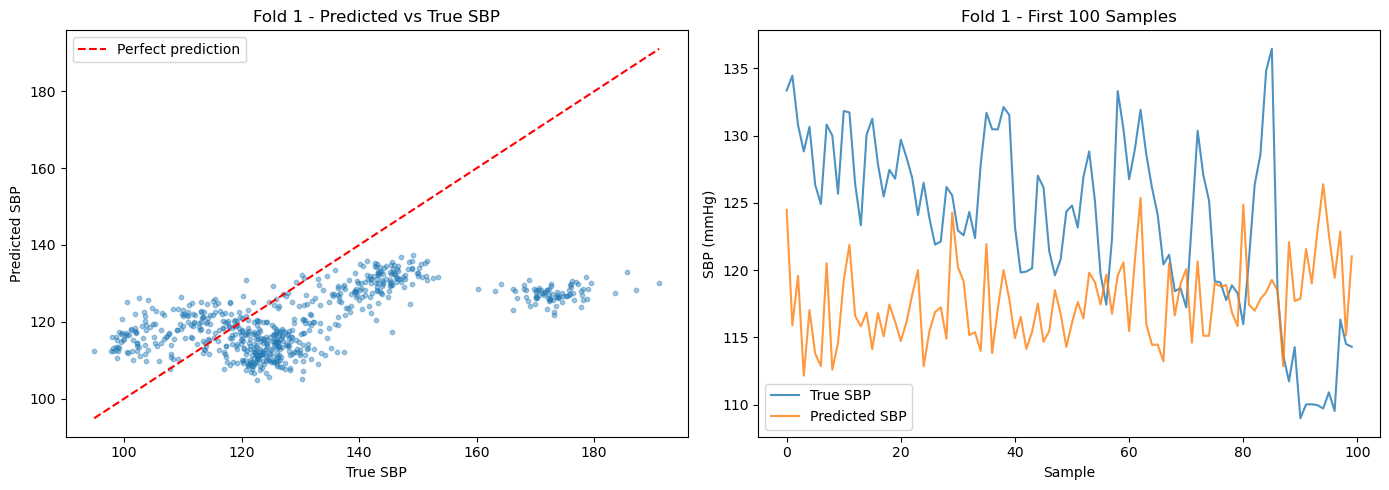

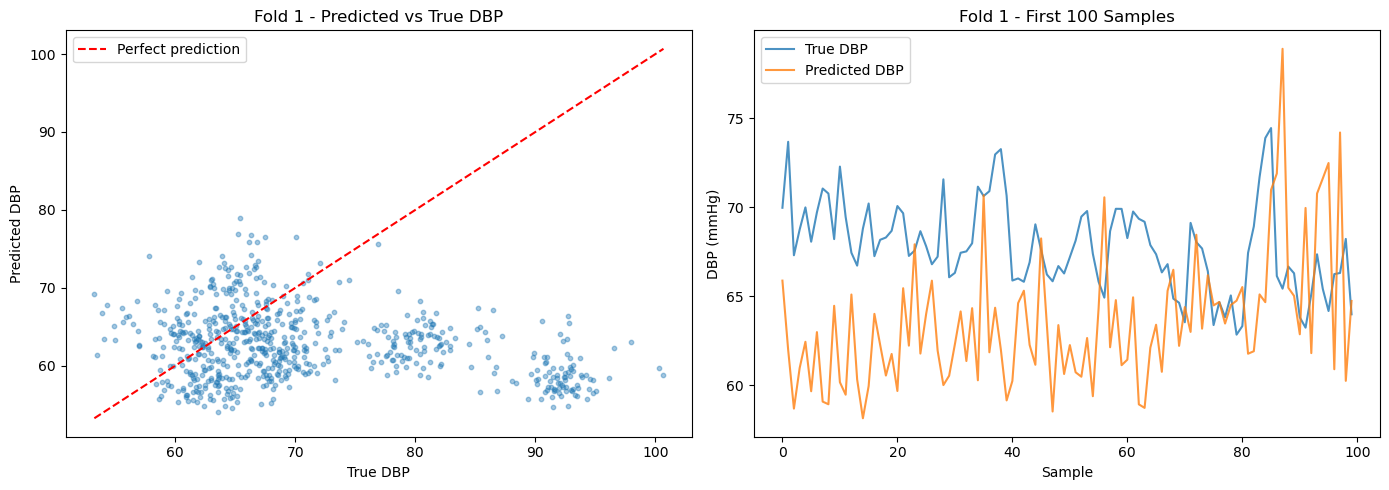


Fold 2/5
 Epoch 1 | Train Loss SBP: 5272.7905 | Train Loss DBP: 1706.1097
 Epoch 2 | Train Loss SBP: 175.4539 | Train Loss DBP: 69.4771
 Epoch 3 | Train Loss SBP: 119.7214 | Train Loss DBP: 54.2117
 Epoch 4 | Train Loss SBP: 102.7028 | Train Loss DBP: 49.3609
 Epoch 5 | Train Loss SBP: 98.0821 | Train Loss DBP: 44.6063
Generalization Error SBP = 13.9788, Generalization Error DBP = 7.9242


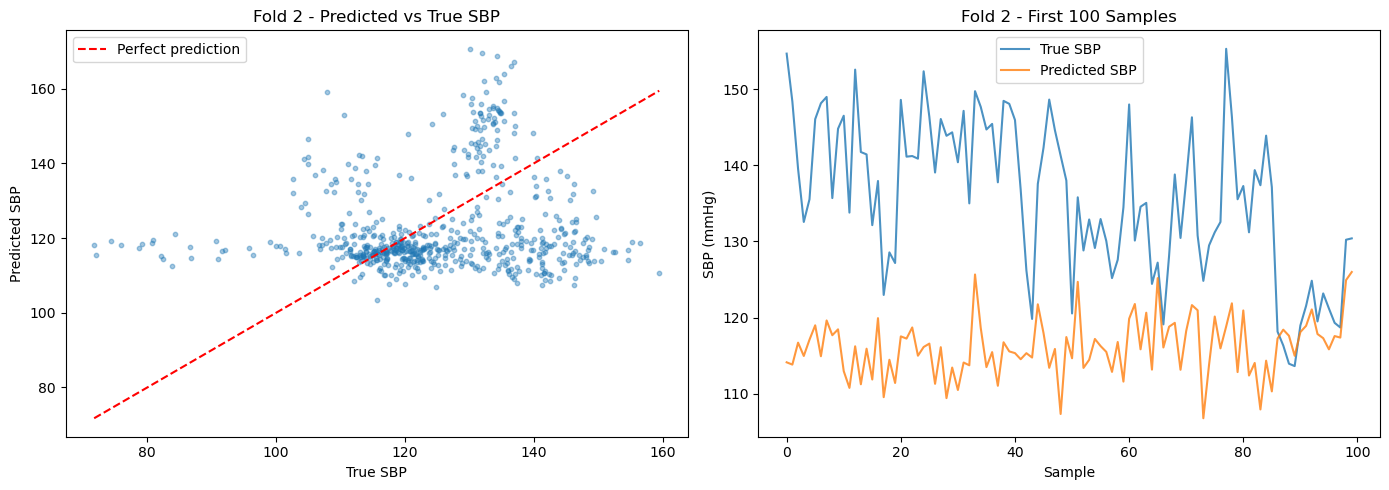

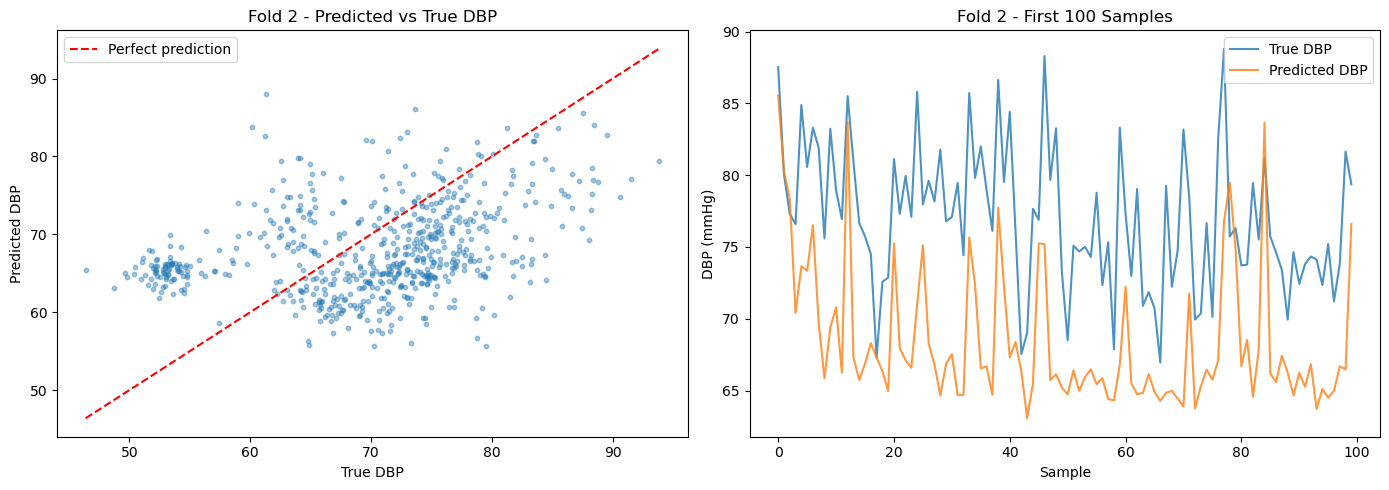


Fold 3/5
 Epoch 1 | Train Loss SBP: 5372.0606 | Train Loss DBP: 1774.0564
 Epoch 2 | Train Loss SBP: 220.8179 | Train Loss DBP: 79.0121
 Epoch 3 | Train Loss SBP: 177.0028 | Train Loss DBP: 62.5523
 Epoch 4 | Train Loss SBP: 151.7259 | Train Loss DBP: 55.5795
 Epoch 5 | Train Loss SBP: 139.0400 | Train Loss DBP: 51.7269
Generalization Error SBP = 8.9887, Generalization Error DBP = 5.3081


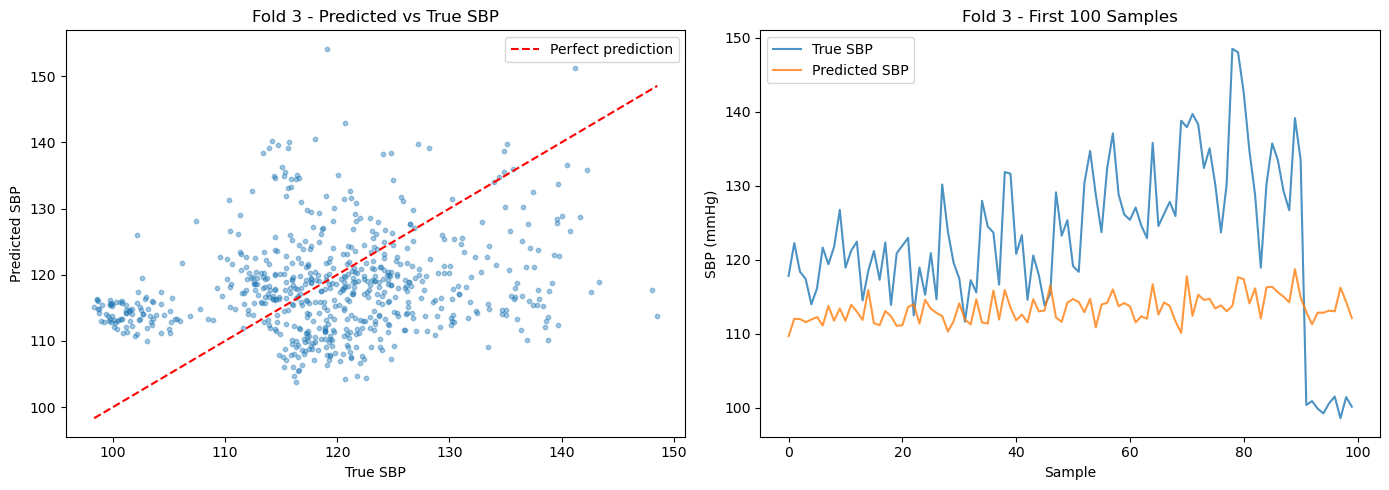

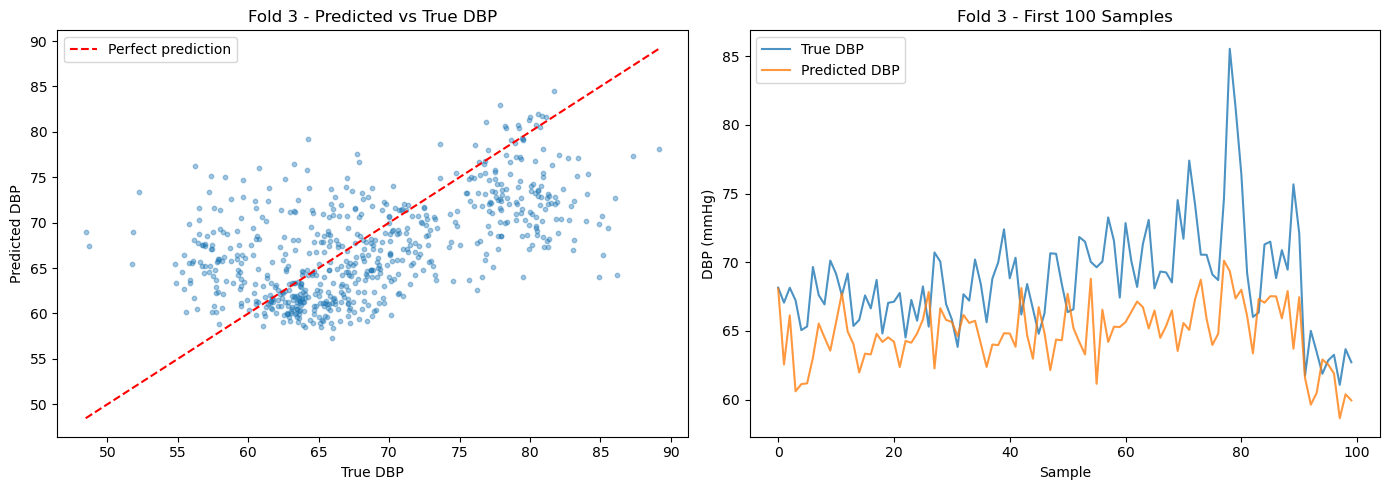


Fold 4/5
 Epoch 1 | Train Loss SBP: 6101.6400 | Train Loss DBP: 2167.6095
 Epoch 2 | Train Loss SBP: 190.6407 | Train Loss DBP: 70.7095
 Epoch 3 | Train Loss SBP: 149.1821 | Train Loss DBP: 56.5803
 Epoch 4 | Train Loss SBP: 133.7437 | Train Loss DBP: 48.1350
 Epoch 5 | Train Loss SBP: 127.8632 | Train Loss DBP: 42.8855
Generalization Error SBP = 10.3538, Generalization Error DBP = 8.8605


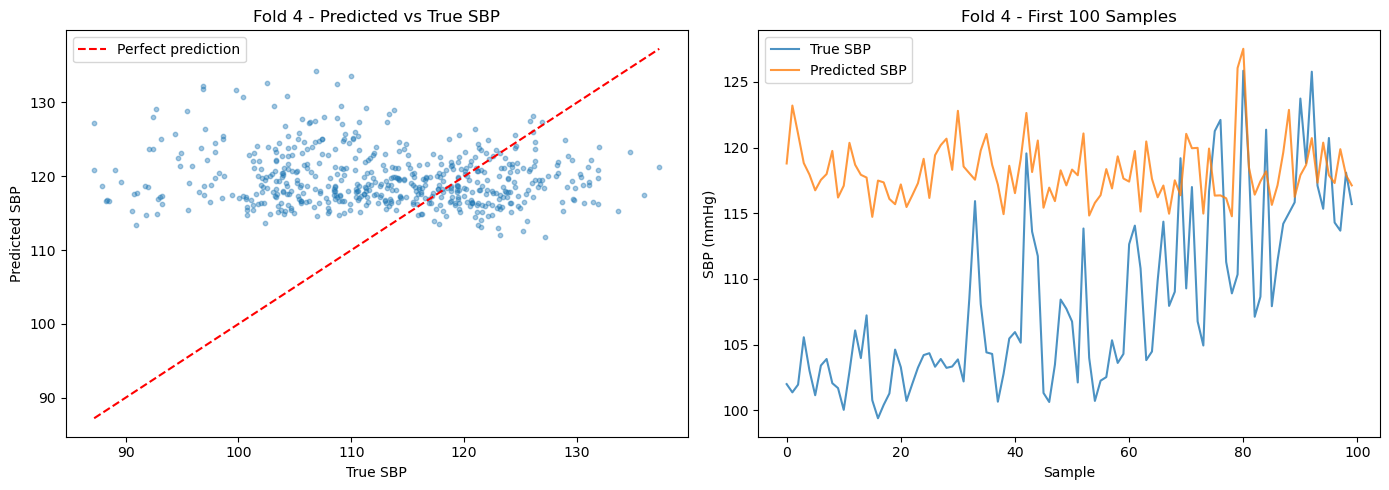

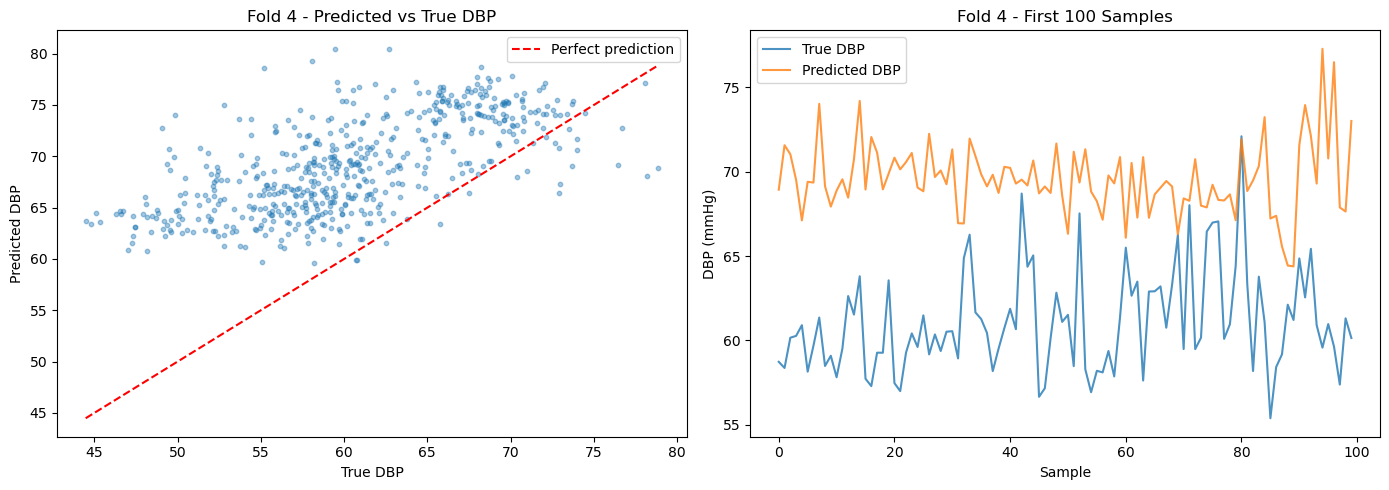


Fold 5/5
 Epoch 1 | Train Loss SBP: 7454.1990 | Train Loss DBP: 1866.1407
 Epoch 2 | Train Loss SBP: 205.5453 | Train Loss DBP: 78.5838
 Epoch 3 | Train Loss SBP: 162.1074 | Train Loss DBP: 60.6952
 Epoch 4 | Train Loss SBP: 138.1878 | Train Loss DBP: 54.2564
 Epoch 5 | Train Loss SBP: 132.0024 | Train Loss DBP: 50.2981
Generalization Error SBP = 9.0069, Generalization Error DBP = 5.4726


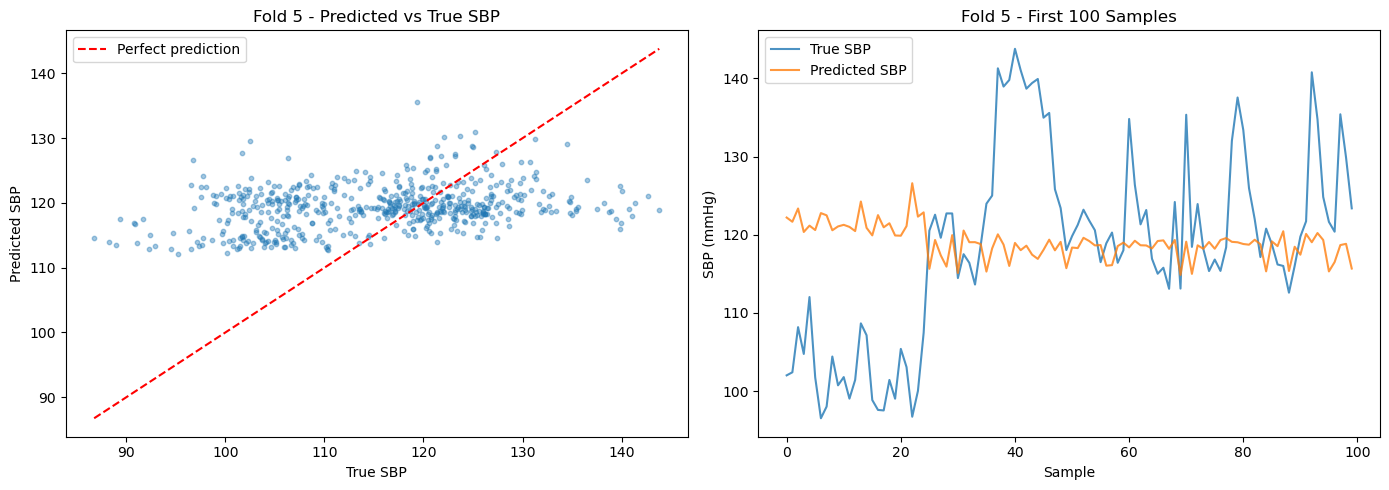

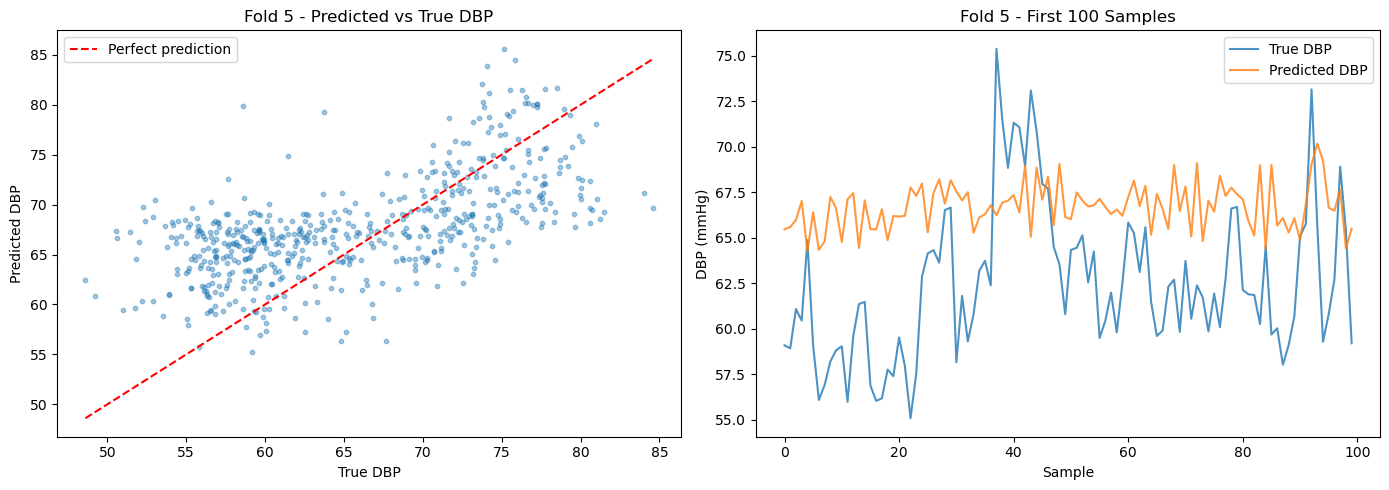


[spikegen] Final CV MAE's: 
SBP: 11.5801 ± 2.5675
DBP: 7.6551 ± 2.0056


In [14]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
most_important_features = ["TdiaToEnd","T_a_norm","S4_norm","TSystoDiaRise", "ppg_histogram_down_2","S4","ppg4_histogram_down_5","T_e_norm","ppg3_histogram_down_8","usdc_2"]


with open("results_RF_importances/rf_results.pkl", "rb") as f:
    ranking = pickle.load(f)

# top_features_SBP = [f for (f, _) in ranking["sbp_ranking"][:30]]
# top_features_DBP = [f for (f, _) in ranking["dbp_ranking"][:30]]

top_features_SBP = [f for (f, _) in ranking["sbp_ranking_pearson"][:27]]
top_features_DBP = [f for (f, _) in ranking["dbp_ranking_pearson"][:27]]


batch_size = 32
num_epochs = 5
num_inputs = 27
num_hidden = 128
num_hidden2 = 64
num_outputs = 100
topk_sbp = 10
topk_dbp = 10

useStratifiedSampling = False
num_bins = 10
max_per_bin = 300

beta_val = 0.7
num_folds = 5
eps = 1e-8

preferred_values_sbp = torch.linspace(70, 190, 100).to(device)
preferred_values_dbp = torch.linspace(45, 101, 100).to(device)

results = {}
# ENCODING_METHODS = ['spikegen', 'uniform', 'beta']
ENCODING_METHODS = ['spikegen']

for encoding_method in ENCODING_METHODS:
    print(f"\n{'='*60}")
    print(f" ENCODING METHOD: {encoding_method.upper()}")
    print(f"{'='*60}")
    
    #loss_fn = SF.
    loss_fn = nn.MSELoss()
    firing_rate_loss_fn = SF.mse_count_loss(correct_rate=0.8, incorrect_rate=0.2)
    #loss_fn = nn.L1Loss() 
    
    cv_mae_sbp = 0.0    # Cross Validation Mean Absolute Error for SBP
    cv_mae_dbp = 0.0
    cv_total_samples = 0
    fold_maes_sbp = []  # To collect per-fold MAE
    fold_maes_dbp = []

    for fold in range(num_folds):
        print(f"\nFold {fold + 1}/{num_folds}")

        all_predictions_sbp = []    # For visualization
        all_true_sbp = []
        all_predictions_dbp = []
        all_true_dbp = []
        
        net_sbp = Net(num_inputs, num_hidden, num_hidden2, num_outputs, beta_val, encoding_method).to(device)
        net_dbp = Net(num_inputs, num_hidden, num_hidden2, num_outputs, beta_val, encoding_method).to(device)
        
        params_before = {name: param.clone().detach() for name, param in net_sbp.named_parameters()}

        optimizer_sbp = optim.Adam(net_sbp.parameters(), lr=5e-4)
        optimizer_dbp = optim.Adam(net_dbp.parameters(), lr=5e-4)

        test_data  = load_data(fold)
        train_data = pd.concat([load_data(i) for i in range(num_folds) if i != fold])

        if useStratifiedSampling == True:
            # Stratified sampling (bin by SBP)
            combined_df = train_data.copy()
            combined_df['SP_bin'] = pd.cut(combined_df.iloc[:, 2], bins=num_bins, duplicates='drop')

            train_data = (
                combined_df
                .groupby('SP_bin', group_keys=False)
                .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=2))
                .reset_index(drop=True)
            )

            if 'SP_bin' in train_data.columns:
                train_data = train_data.drop(columns='SP_bin')


        X_train_sbp = torch.tensor(train_data[top_features_SBP].values, dtype=torch.float32)
        X_train_dbp = torch.tensor(train_data[top_features_DBP].values, dtype=torch.float32)
        X_test_sbp = torch.tensor(test_data[top_features_SBP].values, dtype=torch.float32)
        X_test_dbp = torch.tensor(test_data[top_features_DBP].values, dtype=torch.float32)
        y_train = torch.tensor(train_data.iloc[:, 2:4].values, dtype=torch.float32)
        y_test = torch.tensor(test_data.iloc[:, 2:4].values, dtype=torch.float32)
        
        # per feature SBP normalization
        X_min_sbp = X_train_sbp.min(dim=0).values
        X_max_sbp = X_train_sbp.max(dim=0).values
        X_train_sbp = (X_train_sbp - X_min_sbp) / (X_max_sbp - X_min_sbp + 1e-8)
        X_test_sbp  = (X_test_sbp  - X_min_sbp) / (X_max_sbp - X_min_sbp + 1e-8)

        # per feature DBP normalization
        X_min_dbp = X_train_dbp.min(dim=0).values
        X_max_dbp = X_train_dbp.max(dim=0).values
        X_train_dbp = (X_train_dbp - X_min_dbp) / (X_max_dbp - X_min_dbp + 1e-8)
        X_test_dbp  = (X_test_dbp  - X_min_dbp) / (X_max_dbp - X_min_dbp + 1e-8)
        
        train_loader = DataLoader(
            TensorDataset(X_train_sbp, X_train_dbp, y_train),
            batch_size=batch_size, shuffle=True
        )
        test_loader = DataLoader(
            TensorDataset(X_test_sbp, X_test_dbp, y_test),
            batch_size=batch_size, shuffle=False
        )

        # Training
        for epoch in range(num_epochs):
            net_sbp.train()
            net_dbp.train()
            num_batches = 0
            total_train_loss_sbp = 0
            total_train_loss_dbp = 0
            
            for x_sbp, x_dbp, y in train_loader:
                x_sbp = x_sbp.to(device)
                x_dbp = x_dbp.to(device)
                y = y.to(device)

                optimizer_sbp.zero_grad()
                optimizer_dbp.zero_grad()

                # SBP
                '''
                spk_sbp = [time_steps, batch_size, 100], these is the spiking activity of the model
                fr_sbp = [batch_size, 100], here we average over the timesteps
                topk_idx = select the top k most active neurons (spiked the most on average)
                fr_top = gather their firing rates
                pv_top = gather their pressure values
                pred_sbp = final prediction

                Why Top-K during training? 
                It focuses the loss signal on the neurons that are actually firing meaningfully, ignoring the noisy low-activity neurons.
                This makes the neural network produce a sparse but confident representation. 
                '''
                spk_sbp = net_sbp(x_sbp)
                fr_sbp = spk_sbp.mean(0)
                topk_idx = torch.topk(fr_sbp, topk_sbp, dim=1)[1]
                fr_top = torch.gather(fr_sbp, 1, topk_idx)
                pv_top = preferred_values_sbp[topk_idx]
                pred_sbp = (fr_top * pv_top).sum(1) / (fr_top.sum(1) + eps)

                # DBP
                spk_dbp = net_dbp(x_dbp)
                fr_dbp = spk_dbp.mean(0)
                topk_idx = torch.topk(fr_dbp, topk_dbp, dim=1)[1]
                fr_top = torch.gather(fr_dbp, 1, topk_idx)
                pv_top = preferred_values_dbp[topk_idx]
                pred_dbp = (fr_top * pv_top).sum(1) / (fr_top.sum(1) + eps)

                loss_sbp = loss_fn(pred_sbp, y[:, 0])
                loss_dbp = loss_fn(pred_dbp, y[:, 1])

                loss_sbp.backward()
                
                torch.nn.utils.clip_grad_norm_(net_sbp.parameters(), max_norm=1.0)
                optimizer_sbp.step()

                loss_dbp.backward()
                torch.nn.utils.clip_grad_norm_(net_dbp.parameters(), max_norm=1.0)
                optimizer_dbp.step()


                total_train_loss_sbp += loss_sbp.item()
                total_train_loss_dbp += loss_dbp.item()
                num_batches += 1
            print(f" Epoch {epoch + 1} | Train Loss SBP: {total_train_loss_sbp / num_batches:.4f} "
                  f"| Train Loss DBP: {total_train_loss_dbp / num_batches:.4f}")
            '''
            print(f" Epoch {epoch + 1} | Train Loss SBP: {total_train_loss_sbp / num_batches:.4f} "
                  f"| Train Loss DBP: {total_train_loss_dbp / num_batches:.4f}")
            if fold == 0 and (epoch == 0 or epoch == num_epochs - 1):
                print(f"--- Weight changes after epoch {epoch+1} ---")
                for name, param in net_sbp.named_parameters():
                    diff = (param.detach() - params_before[name]).abs().mean().item()
                    print(f"{name}: mean weight change = {diff:.6f}")
            '''

        # Evaluation
        net_sbp.eval()
        net_dbp.eval()
        total_mae_sbp = 0
        total_mae_dbp = 0
        total_samples = 0
        true_sbp_list = []
        pred_sbp_list = []
        true_dbp_list = []
        pred_dbp_list = []

        with torch.no_grad():
            for x_sbp, x_dbp, y in test_loader:
                x_sbp = x_sbp.to(device)
                x_dbp = x_dbp.to(device)
                y = y.to(device)

                '''
                Here we dont have the topk neurons anymore, we take the average over all 100 neurons. 
                '''
                spk_sbp = net_sbp(x_sbp)
                fr_sbp = spk_sbp.mean(0)
                
                topk_idx = torch.topk(fr_sbp, topk_sbp, dim=1)[1]
                fr_top = torch.gather(fr_sbp, 1, topk_idx)
                pv_top = preferred_values_sbp[topk_idx]
                pred_sbp = (fr_top * pv_top).sum(1) / (fr_top.sum(1) + eps)

                #pred_sbp = (fr_sbp * preferred_values_sbp).sum(1) / (fr_sbp.sum(1) + eps)

                spk_dbp = net_dbp(x_dbp)
                fr_dbp = spk_dbp.mean(0)
                
                topk_idx = torch.topk(fr_dbp, topk_dbp, dim=1)[1]
                fr_top = torch.gather(fr_dbp, 1, topk_idx)
                pv_top = preferred_values_dbp[topk_idx]
                pred_dbp = (fr_top * pv_top).sum(1) / (fr_top.sum(1) + eps)
                
                #pred_dbp = (fr_dbp * preferred_values_dbp).sum(1) / (fr_dbp.sum(1) + eps)

                mae_sbp = torch.abs(pred_sbp - y[:, 0]).sum().item()
                mae_dbp = torch.abs(pred_dbp - y[:, 1]).sum().item()

                true_sbp_list.extend(y[:,0].cpu().numpy())
                pred_sbp_list.extend(pred_sbp.cpu().numpy())

                true_dbp_list.extend(y[:,1].cpu().numpy())
                pred_dbp_list.extend(pred_dbp.cpu().numpy())

                total_mae_sbp += mae_sbp
                total_mae_dbp += mae_dbp
                total_samples += y.shape[0]

        fold_mae_sbp = total_mae_sbp / total_samples
        fold_mae_dbp = total_mae_dbp / total_samples   

        fold_maes_sbp.append(fold_mae_sbp)
        fold_maes_dbp.append(fold_mae_dbp)

        cv_mae_sbp += total_mae_sbp
        cv_mae_dbp += total_mae_dbp
        cv_total_samples += total_samples
        print(f"Generalization Error SBP = {total_mae_sbp / total_samples:.4f}, Generalization Error DBP = {total_mae_dbp / total_samples:.4f}")
        plot_predictions(np.array(true_sbp_list), np.array(pred_sbp_list), "SBP", fold)
        plot_predictions(np.array(true_dbp_list), np.array(pred_dbp_list), "DBP", fold)

    results[encoding_method] = (cv_mae_sbp, cv_mae_dbp)

    print(f"\n[{encoding_method}] Final CV MAE's: \nSBP: {cv_mae_sbp / cv_total_samples:.4f} ± {np.std(fold_maes_sbp):.4f}\nDBP: {cv_mae_dbp / cv_total_samples:.4f} ± {np.std(fold_maes_dbp):.4f}")